In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Run 1/20 - Accuracy: 53.02%
Run 2/20 - Accuracy: 51.51%
Run 3/20 - Accuracy: 50.50%
Run 4/20 - Accuracy: 54.52%
Run 5/20 - Accuracy: 54.77%
Run 6/20 - Accuracy: 54.77%
Run 7/20 - Accuracy: 53.02%
Run 8/20 - Accuracy: 53.02%
Run 9/20 - Accuracy: 48.74%
Run 10/20 - Accuracy: 53.02%
Run 11/20 - Accuracy: 54.52%
Run 12/20 - Accuracy: 51.26%
Run 13/20 - Accuracy: 54.52%
Run 14/20 - Accuracy: 54.27%
Run 15/20 - Accuracy: 51.51%
Run 16/20 - Accuracy: 51.51%
Run 17/20 - Accuracy: 52.01%
Run 18/20 - Accuracy: 52.26%
Run 19/20 - Accuracy: 50.50%
Run 20/20 - Accuracy: 52.26%


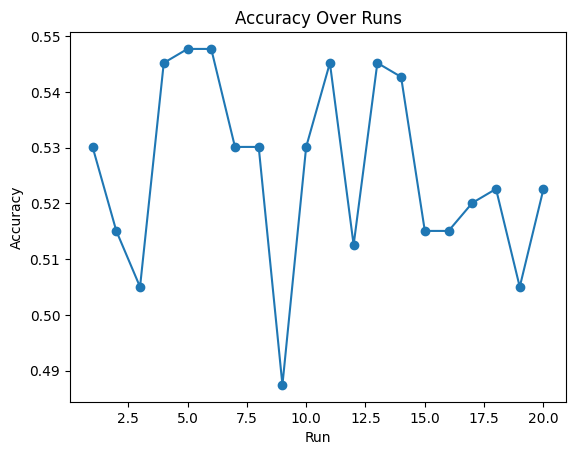

In [15]:
# Step 1: Import libraries
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Step 3: Read the CSV file into a Pandas DataFrame
df = pd.read_csv('/content/drive/MyDrive/stock market/upload_DJIA_table.csv')

# Step 4: Preprocess the data
# For simplicity, let's consider 'Close' as the target variable (you can choose a different one)
target_column = 'Close'

# Convert the 'Date' column to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Create a binary column for classification (e.g., if 'Close' increases, label as 1, otherwise 0)
df['Target'] = (df[target_column].shift(-1) > df[target_column]).astype(int)

# Drop rows with NaN in the 'Target' column (due to shifting)
df = df.dropna()

# Step 5: Split the data into features (X) and target variable (y)
X = df[['Open', 'High', 'Low', 'Close', 'Volume', 'Adj Close']]
y = df['Target']

# Step 6: Specify the number of epochs (in this case, multiple runs with different splits)
epochs = 20
accuracy_values = []

for epoch in range(epochs):
    # Split the data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=epoch)

    # Train the Logistic Regression classifier
    clf = LogisticRegression(max_iter=1000, random_state=42)
    y_pred = clf.fit(X_train, y_train).predict(X_test)

    # Calculate and print the accuracy
    accuracy = accuracy_score(y_test, y_pred)
    accuracy_values.append(accuracy)
    print(f'Run {epoch + 1}/{epochs} - Accuracy: {accuracy * 100:.2f}%')

# Plotting the accuracy graph
plt.plot(range(1, epochs + 1), accuracy_values, marker='o')
plt.title('Accuracy Over Runs')
plt.xlabel('Run')
plt.ylabel('Accuracy')
plt.show()


In [16]:
# Calculate and print the average accuracy
average_accuracy = sum(accuracy_values) / epochs
print(f'\nAverage Accuracy over {epochs} runs: {average_accuracy * 100:.2f}%')



Average Accuracy over 20 runs: 52.58%
